# **Lab 7(B) - Mathematical and Statistical Filters**

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rc('text', usetex=False)

# Load a color image (OpenCV reads BGR) and convert it to RGB
imgPath = 'images/parrot.png'  # Replace with your color image filename
img_bgr = cv2.imread(imgPath, cv2.IMREAD_COLOR)

if img_bgr is None:
    raise FileNotFoundError(f"Could not load {imgPath}. Put the image in the notebook folder.")

img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)


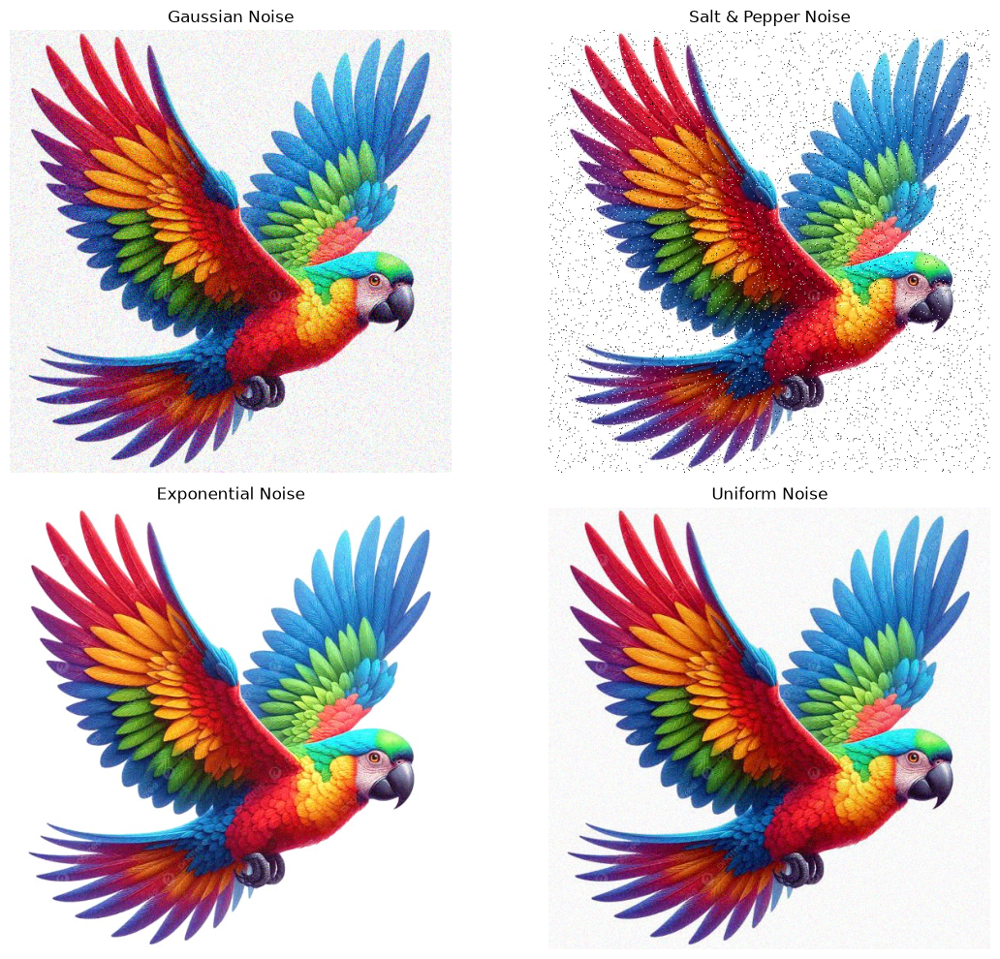

In [2]:
# ========== ( Adding Noise to a Color Image ) =================

def add_noise(image, noise_type):
    # image has shape (height, width, channels)
    image_float = image.astype(np.float32)

    if noise_type == "gaussian":
        mean = 0
        var = 0.01
        sigma = var ** 0.5
        gauss = np.random.normal(mean, sigma, image.shape).astype(np.float32)
        noisy = image_float / 255.0 + gauss
        return np.clip(noisy * 255.0, 0, 255).astype(np.uint8)

    elif noise_type == "salt_pepper":
        noisy = image.copy()
        amount = 0.04
        num_pixels = int(amount * image.shape[0] * image.shape[1])
        ys = np.random.randint(0, image.shape[0], num_pixels)
        xs = np.random.randint(0, image.shape[1], num_pixels)
        salt_count = num_pixels // 2
        noisy[ys[:salt_count], xs[:salt_count]] = 255
        noisy[ys[salt_count:], xs[salt_count:]] = 0
        return noisy

    elif noise_type == "exponential":
        expo = np.random.exponential(scale=10.0, size=image.shape)
        return np.clip(image_float + expo, 0, 255).astype(np.uint8)

    elif noise_type == "uniform":
        uni = np.random.uniform(-20, 20, size=image.shape)
        return np.clip(image_float + uni, 0, 255).astype(np.uint8)

    else:
        raise ValueError("Unknown noise type. Use gaussian, salt_pepper, exponential, or uniform.")

# Generate four noisy color images
noise_gauss = add_noise(img, "gaussian")
noise_sp = add_noise(img, "salt_pepper")
noise_expo = add_noise(img, "exponential")
noise_uni = add_noise(img, "uniform")

# Display results in color
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(noise_gauss), plt.title('Gaussian Noise'), plt.axis('off')
plt.subplot(222), plt.imshow(noise_sp), plt.title('Salt & Pepper Noise'), plt.axis('off')
plt.subplot(223), plt.imshow(noise_expo), plt.title('Exponential Noise'), plt.axis('off')
plt.subplot(224), plt.imshow(noise_uni), plt.title('Uniform Noise'), plt.axis('off')
plt.tight_layout()
plt.show()


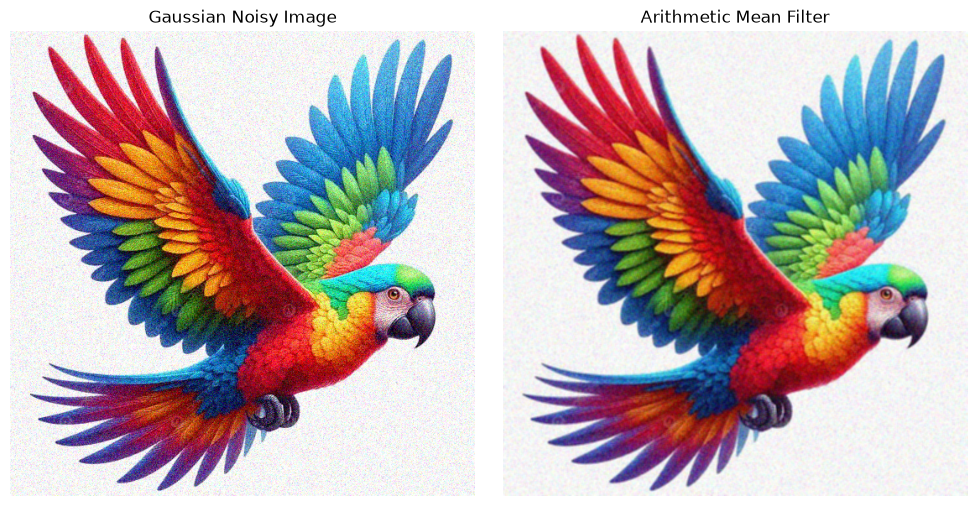

In [3]:
# --- METHOD 1: Built-in Arithmetic Mean Filter ---

# Apply a 3x3 arithmetic mean filter to the Gaussian-noisy color image
filtered_img = cv2.blur(noise_gauss, (3, 3))

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_gauss), plt.title('Gaussian Noisy Image'), plt.axis('off')
plt.subplot(122), plt.imshow(filtered_img), plt.title('Arithmetic Mean Filter'), plt.axis('off')
plt.tight_layout()
plt.show()


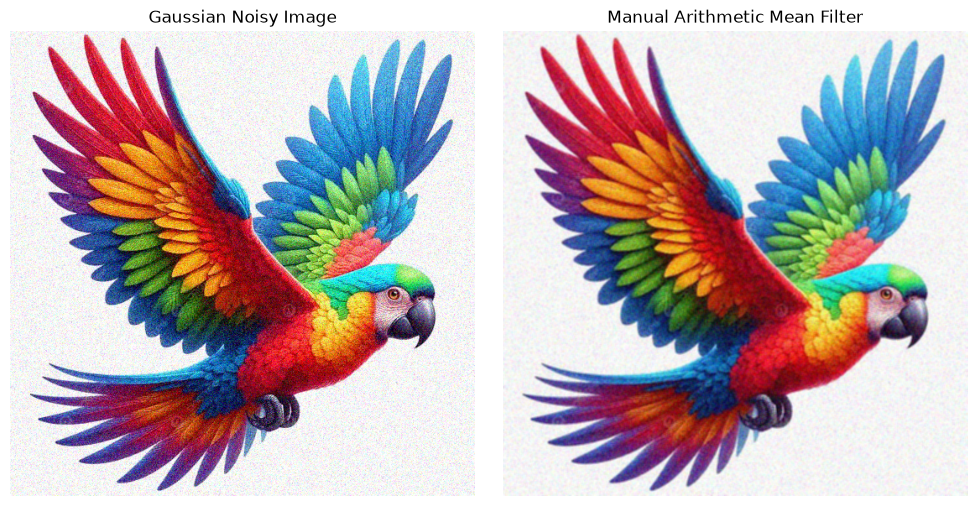

In [4]:
# --- METHOD 2: Manual Arithmetic Mean Filter using a Kernel ---

kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)

# filter2D processes each color channel separately
arithmetic_mean_manual = cv2.filter2D(noise_gauss, -1, kernel)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_gauss), plt.title('Gaussian Noisy Image'), plt.axis('off')
plt.subplot(122), plt.imshow(arithmetic_mean_manual), plt.title('Manual Arithmetic Mean Filter'), plt.axis('off')
plt.tight_layout()
plt.show()


## **Geometric Means**

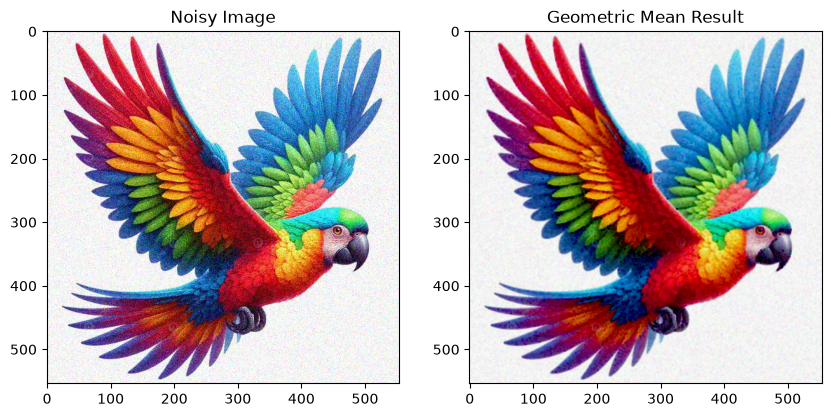

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def geometric_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 and add a tiny epsilon to avoid log(0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Apply the log-transform
    log_img = np.log(img_float)

    # 3. Apply a box filter to the log image (calculates the average of logs)
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    mean_log = cv2.filter2D(log_img, -1, kernel)

    # 4. Take the exponent to get back to the geometric mean
    geo_mean = np.exp(mean_log)

    # 5. Clip and convert back to 8-bit
    return np.clip(geo_mean, 0, 255).astype(np.uint8)


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# Apply filter
result = geometric_mean_filter(noise_img, kernel_size=3)

# Display Comparison
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(result), plt.title('Geometric Mean Result')
plt.show()


## **Harmonic Means Filter**

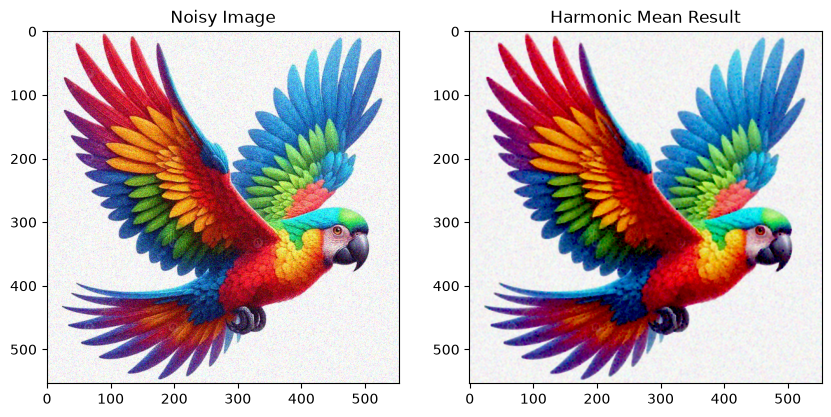

In [6]:

def harmonic_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 to avoid overflow during calculation
    # Add a tiny epsilon to handle black pixels (0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate the reciprocal of every pixel (1/P)
    reciprocal_img = 1.0 / img_float

    # 3. Sum the reciprocals in a window and divide by window size
    # This is equivalent to applying a standard mean filter to the reciprocal image
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    sum_reciprocal = cv2.filter2D(reciprocal_img, -1, kernel)

    # 4. Final step of the formula: (Window Size) / Sum of Reciprocals
    # Note: Window size is kernel_size * kernel_size
    n = kernel_size * kernel_size
    harmonic_mean = n / sum_reciprocal

    # 5. Clip the results and convert back to 8-bit
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# Apply the filter
cleaned_img = harmonic_mean_filter(noise_img, kernel_size=3)

# Display Comparison
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(cleaned_img), plt.title('Harmonic Mean Result')
plt.show()


## **Contra - Harmonic Mean Filter**

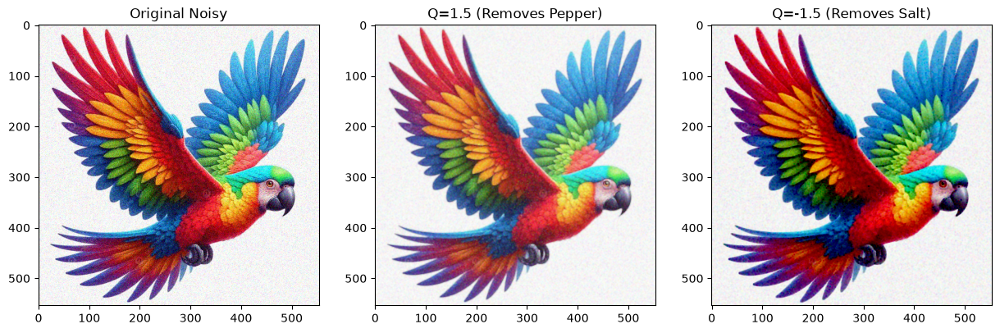

In [7]:


def contra_harmonic_mean(image, kernel_size=3, Q=0):
    # 1. Convert to float to handle high powers and prevent overflow
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate numerator: Sum of pixels to the power (Q + 1)
    numerator = np.power(img_float, Q + 1)
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    num_sum = cv2.filter2D(numerator, -1, kernel)

    # 3. Calculate denominator: Sum of pixels to the power (Q)
    denominator = np.power(img_float, Q)
    den_sum = cv2.filter2D(denominator, -1, kernel)

    # 4. Divide and clean up
    # Handle potential division by zero
    result = num_sum / (den_sum + 1e-6)

    return np.clip(result, 0, 255).astype(np.uint8)

# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# --- APPLICATIONS ---
# Q > 0 (e.g., 1.5): Removes Pepper Noise (black spots)
pepper_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=1.5)

# Q < 0 (e.g., -1.5): Removes Salt Noise (white spots)
salt_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=-1.5)

# --- DISPLAY ---
plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noise_img), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(pepper_removed), plt.title('Q=1.5 (Removes Pepper)')
plt.subplot(133), plt.imshow(salt_removed), plt.title('Q=-1.5 (Removes Salt)')
plt.show()


## **Median Filter**

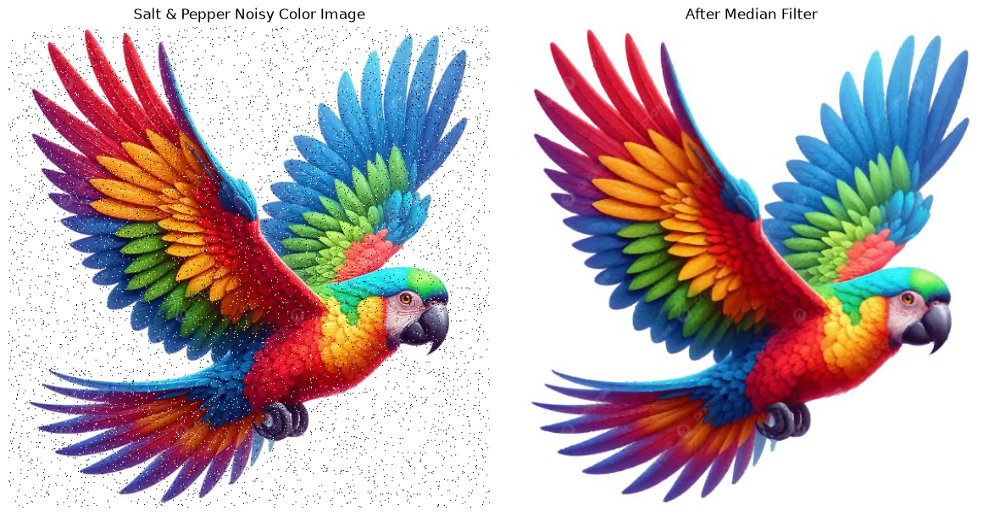

In [8]:



# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_sp

# 2. Apply Median Filter
# The second argument is the 'ksize' (kernel size).
# It MUST be an odd integer (3, 5, 7, etc.)
median_result = cv2.medianBlur(noise_img, 3)

# 3. Compare Results
plt.figure(figsize=(12, 6))

plt.subplot(121), plt.imshow(noise_img), plt.title('Salt & Pepper Noisy Color Image'), plt.axis('off')
plt.subplot(122), plt.imshow(median_result), plt.title('After Median Filter'), plt.axis('off')
plt.tight_layout()
plt.show()


## **Max and Min Filter**

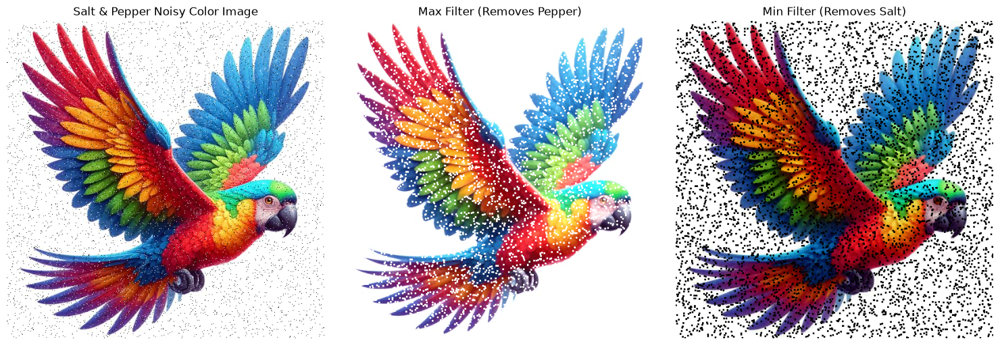

In [9]:


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_sp



# 2. Define the Kernel size (e.g., 3x3)
kernel = np.ones((3, 3), np.uint8)

# 3. Apply Max Filter (Dilation)
# This picks the brightest pixel in the neighborhood.
max_filter = cv2.dilate(noise_img, kernel)

# 4. Apply Min Filter (Erosion)
# This picks the darkest pixel in the neighborhood.
min_filter = cv2.erode(noise_img, kernel)

# --- Display Results ---
plt.figure(figsize=(15, 5))

plt.subplot(131), plt.imshow(noise_img), plt.title('Salt & Pepper Noisy Color Image')
plt.subplot(132), plt.imshow(max_filter), plt.title('Max Filter (Removes Pepper)')
plt.subplot(133), plt.imshow(min_filter), plt.title('Min Filter (Removes Salt)')

for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()


## **Mid-Point Filtering**

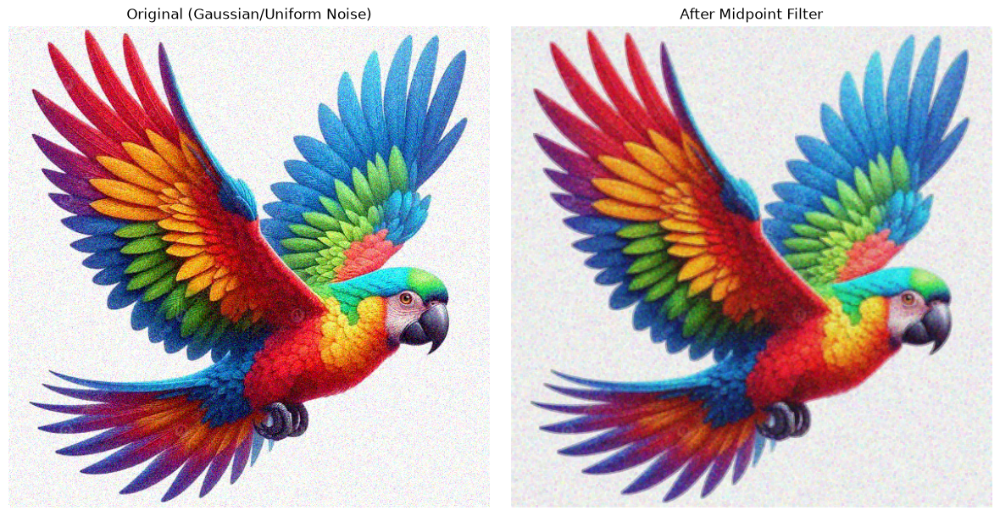

In [10]:

def midpoint_filter(image, kernel_size=3):
    # 1. Define the structural element (kernel)
    kernel = np.ones((kernel_size, kernel_size), np.uint8)

    # 2. Find the Maximum value in the neighborhood (Dilation)
    max_img = cv2.dilate(image, kernel).astype(np.float64)

    # 3. Find the Minimum value in the neighborhood (Erosion)
    min_img = cv2.erode(image, kernel).astype(np.float64)

    # 4. Calculate the average of Max and Min
    midpoint = (max_img + min_img) / 2

    # 5. Convert back to 8-bit
    return midpoint.astype(np.uint8)



# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss


# Apply the Midpoint Filter
result = midpoint_filter(noise_img, kernel_size=3)

# --- Display Results ---
plt.figure(figsize=(12, 6))

plt.subplot(121), plt.imshow(noise_img), plt.title('Original (Gaussian/Uniform Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(result), plt.title('After Midpoint Filter'), plt.axis('off')

plt.tight_layout()
plt.show()
